# 유전자 변이 기반 암 아형(SUBCLASS) 분류 — 최종 제출 코드

**대회**: 데이콘 [초격차] AI 헬스케어 7기 해커톤 · **평가 지표**: Macro F1 · **최종 모델**: LightGBM(시드 앙상블) + 로지스틱 회귀 소프트 보팅

**제출 정보**
- 데이터 입출력 경로: `./data` (`train.csv`, `test.csv`, `sample_submission.csv`를 이 폴더에 넣고 실행 → 제출 파일과 모델 파일도 `./data`에 저장)
- 파일 인코딩: UTF-8
- 사전 학습 모델: **사용하지 않음** (외부 데이터·사전 학습 모델 없이 대회 데이터만 사용)
- 실행 환경: Google Colab (CPU) · OS와 라이브러리 버전은 **0장** 셀 실행 결과에 기록됩니다
- 추론에 쓴 모델 파일: **12장**에서 `./data/model/`에 저장

**전체 흐름**
1. **전처리**: Test의 결측치(NaN)를 고정값 `WT`(변이 없음)로 채우고, 변이 문자열을 종류별(침묵·미스센스·넌센스·프레임시프트)로 파싱합니다.
2. **피처 생성**
   - 기본: 변이 토큰(`TP53`, `TP53__R273H`, `TP53__TRUNC`) 희소 행렬 + 행 단위 변이 통계
   - 1차: 변이 비율, 다중 변이, 과변이 여부, 핫스팟 변이 수
   - 2차: 아미노산 치환(`R>H`), 변이 위치(코돈) 토큰, 넌센스·프레임시프트 분리, 데이터 기반 유전자 그룹
   - 3차: 치환 100종 비율, 아미노산 성질 그룹 변화(소수성·극성·전하 등)
   - 최종: 유전자별 암종 분포 점수(나이브 베이즈, 중첩 교차검증), LightGBM 전용 피처(유전자 쌍 동시 변이, 조합 통계, 위치 구간)
3. **그룹 5-Fold 교차검증**: 변이 프로필이 똑같은 환자(KIPAN↔KIRC, GBMLGG↔LGG 중복)를 같은 fold에 묶습니다.
4. **LightGBM + 로지스틱 회귀 앙상블**: 가중치는 OOF Macro F1로 정합니다.
5. **전체 Train 재학습 → Test 예측**: LightGBM은 시드 3개로 학습해 확률을 평균합니다.
6. **후처리 (중복 프로필 규칙)**: Train 환자와 변이 프로필이 똑같은 Test 환자는 짝 코호트 라벨(KIRC↔KIPAN, LGG↔GBMLGG)로 예측합니다.

**리더보드 기록**: 보정값 제거 0.3246 → 1차 피처 0.3355 → 2차 0.3727 → 3차 0.3848 → 최종(이 노트북)

**Data Leakage 방지**
- 파싱·통계·프로필 해시는 **각 행 안에서만** 계산합니다. 중복 프로필 규칙의 짝 라벨 목록은 Train으로만 만듭니다.
- 결측치는 Test 통계가 아닌 **고정값 `WT`**로 채웁니다.
- 어휘(Vectorizer)·LabelEncoder·기준값·핫스팟/코돈/유전자 목록·나이브 베이즈·모델은 **Train(학습 fold)으로만** 학습하고, Test에는 적용만 합니다.
- Test로 EDA를 하지 않고, `get_dummies`·스케일링·인코딩에 Test를 쓰지 않습니다.


## 0. 라이브러리 설치 및 실행 환경

처음 한 번만 실행합니다. Colab에는 LightGBM이 기본으로 설치되어 있습니다.

In [1]:
!pip install -q lightgbm koreanize-matplotlib

In [2]:
import sys, platform
import numpy, pandas, scipy, sklearn, lightgbm, matplotlib

# 개발 환경(OS) 및 라이브러리 버전 기록
print('OS          :', platform.platform())
print('Python      :', sys.version.split()[0])
for lib in (numpy, pandas, scipy, sklearn, lightgbm, matplotlib):
    print(f'{lib.__name__:<12}:', lib.__version__)

OS          : Linux-6.6.159+-x86_64-with-glibc2.39
Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scipy       : 1.16.3
sklearn     : 1.6.1
lightgbm    : 4.6.0
matplotlib  : 3.10.0


## 1. 환경 설정

In [3]:
import os, re, random, time, pickle
from collections import Counter
import numpy as np
import pandas as pd
import scipy.sparse as sp
import lightgbm as lgb

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
seed_everything()
# ===== 데이터 입출력 경로 =====
DATA_DIR = '/content/sample_data'                              # 입력: train.csv, test.csv, sample_submission.csv
MODEL_DIR = os.path.join(DATA_DIR, 'model')      # 출력: 추론에 쓴 모델 파일
os.makedirs(MODEL_DIR, exist_ok=True)

USE_NEW_FEATURES = True     # 1차 새 피처 (리더보드 0.3355)
USE_MORE_FEATURES = True    # 2차 확장 피처 (아미노산 치환, 코돈 토큰, 넌센스/프레임시프트, 유전자 그룹) — 리더보드 0.3727
USE_AA_GROUPS = True        # 3차: 아미노산 성질 그룹 변화 비율 (LightGBM용) — 리더보드 0.3848
USE_NB_FEATURES = True      # 최종: 유전자별 암종 분포 점수 (나이브 베이즈, 중첩 CV)
SEEDS = [42, 7, 2026]       # 최종: 시드 앙상블 (최종 학습 시드 목록, [42]로 두면 끔)
# LightGBM 전용 피처 (로지스틱 회귀가 표현하지 못하는 정보)
USE_PAIR_FEATURES = True    # ① 함께 생긴 변이 유전자 쌍 (예: IDH1 + ATRX)
USE_COMBO_FEATURES = True   # ② 변이 부담 × 변이 종류 조합 통계
USE_POS_BINS = False        # ③ 단백질 위치 구간 토큰 (예: PIK3CA 1000~1049번) — 효과 없어 끔
# 후처리
USE_DUP_RULE = True         # Train과 변이 프로필이 똑같은 Test 환자 → 짝 코호트 라벨 (KIRC↔KIPAN, LGG↔GBMLGG)

## 2. 데이터 불러오기

In [4]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'), encoding='utf-8')
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'), encoding='utf-8')
submission = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'), encoding='utf-8')

GENES = [c for c in train.columns if c not in ('ID', 'SUBCLASS')]
assert [c for c in test.columns if c != 'ID'] == GENES
print('train:', train.shape, '| test:', test.shape)

le = LabelEncoder().fit(train['SUBCLASS'])     # Train 정답으로만 fit
y = le.transform(train['SUBCLASS'])
K = len(le.classes_)

train: (6201, 4386) | test: (2546, 4385)


## 2-1. 전처리: 결측치 확인 및 처리

이 데이터에서 "변이 없음"은 NaN이 아니라 **`WT`(Wild Type)** 값으로 표시됩니다.
- Train에는 NaN이 없고, Test에는 일부 칸(약 237칸, 128명)에 NaN이 있습니다.
- 처리하지 않으면 NaN이 `'nan'`이라는 글자가 되어 **"변이가 있는 것"으로 잘못 계산**됩니다.
- 결측 = 변이 없음으로 보고 **고정값 `WT`**로 채웁니다. 평균·최빈값 같은 Test 통계를 쓰지 않으므로 규정 위반이 아닙니다.

In [5]:
print('NaN 칸 수 — train:', int(train[GENES].isnull().sum().sum()), '| test:', int(test[GENES].isnull().sum().sum()))
print('빈 문자열 칸 수 — train:', int((train[GENES] == '').sum().sum()))

def fill_missing(df):
    df = df.copy()
    df[GENES] = df[GENES].fillna('WT').astype(str).replace({'': 'WT', 'nan': 'WT'})
    return df

train, test = fill_missing(train), fill_missing(test)
print('처리 후 NaN 칸 수 — test:', int(test[GENES].isnull().sum().sum()))
print(f"전체 칸 중 WT 비율 (train): {(train[GENES] == 'WT').values.mean():.2%}  → 매우 희소한 데이터")

NaN 칸 수 — train: 0 | test: 237
빈 문자열 칸 수 — train: 0
처리 후 NaN 칸 수 — test: 0
전체 칸 중 WT 비율 (train): 99.19%  → 매우 희소한 데이터


## 3. 그룹 교차검증 (중복 프로필을 같은 fold로)

In [6]:
groups = pd.util.hash_pandas_object(train[GENES], index=False).values   # 행 단위 해시
print('중복 프로필 행 수:', pd.Series(groups).duplicated(keep=False).sum())
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, y, groups))

중복 프로필 행 수: 1016


## 4. 전처리: 변이 파싱 (행 단위)

한 칸의 값은 `WT`, `V600E` 또는 `Q369* I368N`처럼 **공백으로 구분된 여러 변이**일 수 있어, 공백으로 나눠 하나씩 처리합니다. 변이는 세 종류로 나눕니다.

| 종류 | 판단 기준 | 예시 | 의미 |
|---|---|---|---|
| 침묵(silent) | 앞뒤 아미노산이 같음 | `R895R` | 단백질 변화 없음 |
| 절단(truncating) | `*`(넌센스) 또는 `fs`(프레임시프트) 포함 | `Q369*`, `K120fs` | 단백질이 끊기거나 파괴됨 |
| 미스센스(missense) | 그 외 아미노산 치환 | `V600E` | 아미노산 하나가 바뀜 |

환자마다 두 개의 토큰 문서를 만듭니다.
- **all 문서**: 변이가 있는 모든 유전자 (침묵 포함)
- **ns 문서**: 아미노산이 바뀌는 변이 유전자 + 구체적 변이(`TP53__R273H`) + 절단 변이(`TP53__TRUNC`)

In [7]:
SILENT = re.compile(r'^([A-Z])\d+\1$')            # 예: R895R (아미노산 변화 없음)
PARSE  = re.compile(r'^([A-Z*\-]+?)(\d+)(.*)$')       # 예: R132H → ('R', '132', 'H'), K120fs → ('K', '120', 'fs')

def build_docs(df, genes=GENES):
    docs_all, docs_ns, docs_codon, docs_trans, stats = [], [], [], [], []
    for row in df[genes].itertuples(index=False):
        tok_all, tok_ns, tok_codon, tok_trans = [], [], [], []
        n_gene = n_total = n_silent = n_trunc = n_missense = 0
        n_nonsense = n_frameshift = n_multi_gene = max_mut_in_gene = 0
        for gene, value in zip(genes, row):
            if value == 'WT':
                continue
            n_gene += 1
            muts = str(value).split()
            n_multi_gene += len(muts) > 1
            max_mut_in_gene = max(max_mut_in_gene, len(muts))
            for mut in muts:
                n_total += 1
                tok_all.append(gene)
                if SILENT.match(mut):
                    n_silent += 1
                    continue
                tok_ns += [gene, f'{gene}__{mut}']
                p = PARSE.match(mut)
                if p:
                    tok_codon.append(f'{gene}__{p.group(1)}{p.group(2)}')     # 변이 위치(코돈): IDH1__R132
                if 'fs' in mut or mut.endswith('*'):
                    n_trunc += 1
                    tok_ns.append(f'{gene}__TRUNC')
                    if 'fs' in mut: n_frameshift += 1
                    else:           n_nonsense += 1
                else:
                    n_missense += 1
                    if p and len(p.group(1)) == 1 and len(p.group(3)) == 1:
                        tok_trans.append(f'{p.group(1)}>{p.group(3)}')       # 아미노산 치환: R>H
        docs_all.append(' '.join(tok_all))
        docs_ns.append(' '.join(tok_ns))
        docs_codon.append(' '.join(dict.fromkeys(tok_codon)))
        docs_trans.append(' '.join(tok_trans))
        tot = max(n_total, 1)
        row_stats = [n_gene, n_total, n_silent, n_trunc, n_missense,          # 앞 5개: 로지스틱 회귀도 사용
                     n_silent / tot, n_trunc / tot]
        if USE_NEW_FEATURES:
            row_stats += [n_missense / tot, n_multi_gene, max_mut_in_gene]
        if USE_MORE_FEATURES:
            row_stats += [n_nonsense, n_frameshift, n_nonsense / tot, n_frameshift / tot]
        stats.append(row_stats)
    return docs_all, docs_ns, docs_codon, docs_trans, np.array(stats, dtype=np.float32)

t0 = time.time()
tr_all, tr_ns, tr_codon, tr_trans, tr_stat = build_docs(train)
te_all, te_ns, te_codon, te_trans, te_stat = build_docs(test)
pick = lambda lst, idx: [lst[i] for i in idx]
STAT_NAMES = ['n_gene', 'n_total', 'n_silent', 'n_trunc', 'n_missense', 'silent_ratio', 'trunc_ratio']
if USE_NEW_FEATURES:
    STAT_NAMES += ['missense_ratio', 'n_multi_gene', 'max_mut_in_gene']
if USE_MORE_FEATURES:
    STAT_NAMES += ['n_nonsense', 'n_frameshift', 'nonsense_ratio', 'frameshift_ratio']
print(f'파싱 완료 ({time.time()-t0:.0f}s) | 행 단위 통계 피처 {len(STAT_NAMES)}개')
print('예시 코돈 토큰:', tr_codon[1][:100])
print('예시 치환 토큰:', tr_trans[1][:60])

파싱 완료 (20s) | 행 단위 통계 피처 14개
예시 코돈 토큰: ABCC8__T1115 ATRX__L1854 DTX1__R36 FN3K__R69 GPR182__A372 HELZ2__A1690 ITGA3__G692 KLF5__C375 PLG__P
예시 치환 토큰: T>M R>H R>Q A>T A>V P>Q M>I K>M R>H


## 4-1. 피처 생성

| 피처 | 설명 | 계산 기준 |
|---|---|---|
| `n_gene`, `n_total` | 변이 유전자 수 / 총 변이 수 (변이 부담) | 행 단위 |
| `n_silent`, `n_trunc`, `n_missense` | 변이 종류별 개수 | 행 단위 |
| `silent_ratio`, `trunc_ratio` | 침묵·절단 변이 비율 | 행 단위 |
| `missense_ratio` | 미스센스 변이 비율 (암종마다 변이 기전이 달라 비율이 다름) | 행 단위 |
| `n_multi_gene` | 한 유전자에 변이가 2개 이상인 유전자 수 | 행 단위 |
| `max_mut_in_gene` | 한 유전자 안의 최대 변이 수 | 행 단위 |
| `hypermutated` | 총 변이 수가 **학습 데이터 상위 10%** 기준을 넘는지 (과변이 암: MSI 대장암, 흑색종 등) | 기준값은 **학습 fold로** |
| `n_hotspot` | 학습 데이터에서 **10명 이상**에게 나온 구체적 변이(핫스팟)를 몇 개 가졌는지 | 핫스팟 목록은 **학습 fold로** |

- 표시는 이번에 새로 추가한 피처이며, `USE_NEW_FEATURES = False`면 모두 빠집니다.
- `hypermutated`, `n_hotspot`은 기준을 데이터에서 정해야 하므로 5장의 `TreeFeaturizer.fit()`에서 **학습 fold로만** 정합니다.

### 2차 확장 피처 (`USE_MORE_FEATURES = True`)

| 피처 | 설명 | 계산 기준 |
|---|---|---|
| **아미노산 치환 패턴** | 미스센스 변이를 `R>H`, `E>K`처럼 "원래 아미노산>바뀐 아미노산"으로 요약. 흡연·자외선·DNA 복구 결함 등 **암종마다 다른 돌연변이 원인**이 특정 치환을 많이 만듦 | 트리: 학습 fold에서 가장 흔한 치환 `N_TRANS`개의 비율(÷ 미스센스 수) / 로지스틱 회귀: TF-IDF |
| **변이 위치(코돈) 토큰** | `IDH1__R132`처럼 바뀐 아미노산을 빼고 위치만 남긴 토큰. R132H와 R132C처럼 **같은 자리의 다른 변이**를 하나로 묶어, 드문 변이도 핫스팟 자리면 신호로 활용 | 학습 fold 어휘 (트리 `MIN_DF`회, 로지스틱 2회 이상) |
| `n_nonsense`, `n_frameshift` (+ 비율) | 절단 변이를 넌센스(`*`)와 프레임시프트(`fs`)로 분리. 프레임시프트는 DNA 복구 결함(MSI) 암에서 많음 | 행 단위 |
| `n_trunc_prone` | **학습 데이터에서 절단 변이가 주로 생기는 유전자**(절단 환자 15명 이상 & 변이 환자 중 절단 비율 50% 이상)에 절단 변이가 몇 개 있는지 — 종양 억제 유전자의 기능 상실 신호를 데이터로 찾음 | 유전자 목록은 **학습 fold로** |
| `n_recurrent_codon` | 학습 데이터에서 **10명 이상에게 변이가 생긴 위치(코돈)**를 몇 개 가졌는지 — 정확히 같은 변이가 아니어도 핫스팟 자리면 셈 | 위치 목록은 **학습 fold로** |

> 사전 실험(통계 피처만 쓴 간이 부스팅 모델, 그룹 5-Fold): 기존 통계 0.129 → +넌센스/프레임시프트 0.152 → +치환 비율 0.252 → +유전자 그룹 0.212 → **모두 0.301**


### 3차 변경 (LightGBM용)

| 변경 | 내용 |
|---|---|
| `N_TRANS` 20 → **100** | 학습 fold에서 가장 흔한 아미노산 치환 100개의 비율을 사용 (드문 치환도 암종 신호를 담음) |
| **아미노산 성질 그룹 변화** (`USE_AA_GROUPS`) | 20종 아미노산을 성질에 따라 6그룹으로 묶고(소수성 `H`: A V I L M F W C / 극성 `P`: S T N Q Y / 양전하 `+`: K R H / 음전하 `-`: D E / 특수 구조 `G`(글리신), `Pro`(프롤린)), 미스센스 변이가 **어느 그룹에서 어느 그룹으로 바뀌었는지** 최대 36가지 비율(÷ 미스센스 수)을 추가. 예: `R>H`는 `+>+`, `E>K`는 `->+`(전하 반전) |

> 아미노산 성질 분류는 일반 생화학 지식이며 외부 데이터가 아닙니다. 비율 계산은 행 단위, 어휘는 학습 fold로만 정합니다.


In [8]:
# 새 피처 미리보기 (Train만 사용, 행 단위 값)
print(pd.DataFrame(tr_stat, columns=STAT_NAMES).describe().T[['mean', '50%', 'max']].round(3).to_string())

                    mean     50%     max
n_gene            35.300  14.000  2393.0
n_total           41.149  14.000  9972.0
n_silent          10.786   3.000  3616.0
n_trunc            3.764   1.000   342.0
n_missense        26.599   9.000  6014.0
silent_ratio       0.224   0.227     1.0
trunc_ratio        0.115   0.088     1.0
missense_ratio     0.645   0.660     1.0
n_multi_gene       3.552   0.000  2021.0
max_mut_in_gene    1.535   1.000    64.0
n_nonsense         2.165   1.000   335.0
n_frameshift       1.598   1.000   139.0
nonsense_ratio     0.051   0.026     1.0
frameshift_ratio   0.064   0.015     1.0


## 5. 트리용 특징

트리 모델은 스케일에 영향을 받지 않으므로 TF-IDF 대신 **이진 표시(0/1)**를 씁니다.
학습 fold에서 너무 드문 토큰(`MIN_DF`회 미만)은 빼서 특징 수와 학습 시간을 줄입니다.
`USE_NEW_FEATURES = True`면 `hypermutated`, `n_hotspot` 피처의 기준값(과변이 기준, 핫스팟 목록)도 여기서 **학습 데이터로만** 정합니다.

In [9]:
MIN_DF = 3
TOKEN_KW = dict(token_pattern=r'\S+', lowercase=False, binary=True, dtype=np.float32)

HOTSPOT_MIN = 10     # 학습 데이터에서 이 인원 이상에게 나온 구체적 변이를 핫스팟으로 간주

N_TRANS = 100                         # 트리용: 학습 fold에서 가장 흔한 아미노산 치환 개수 (3차: 20 → 100)
AA_GROUP = {**{a: 'H' for a in 'AVILMFWC'}, **{a: 'P' for a in 'STNQY'}, **{a: '+' for a in 'KRH'},
            **{a: '-' for a in 'DE'}, 'G': 'G', 'P': 'Pro'}     # 아미노산 성질 그룹 (일반 생화학 분류)

def to_group_doc(doc):
    """행 단위: 치환 토큰 'R>H' → 성질 그룹 변화 토큰 '+>+'"""
    out = []
    for t in doc.split():
        r, a = t.split('>')
        if r in AA_GROUP and a in AA_GROUP:
            out.append(f'{AA_GROUP[r]}>{AA_GROUP[a]}')
    return ' '.join(out)
TRUNC_MIN, TRUNC_SHARE = 15, 0.5      # 절단 경향 유전자 기준
CODON_MIN = 10                        # 반복 변이 위치(코돈) 기준

class TreeFeaturizer:
    def fit(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        self.v_all = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_all)
        self.v_ns  = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_ns)
        names = (list(self.v_all.get_feature_names_out()) +
                 [f'ns:{t}' for t in self.v_ns.get_feature_names_out()] + STAT_NAMES)
        if USE_NEW_FEATURES:                                   # 기준값은 학습 데이터로만
            self.hyper_thr = np.quantile(stat[:, 1], 0.90)
            tok = self.v_ns.transform(docs_ns)
            vocab = self.v_ns.get_feature_names_out().astype(str)
            is_mut = np.char.find(vocab, '__') >= 0
            is_trunc = np.char.endswith(vocab, '__TRUNC')
            self.hot_cols = np.where((np.asarray(tok.sum(0)).ravel() >= HOTSPOT_MIN) & is_mut & ~is_trunc)[0]
            names += ['hypermutated', 'n_hotspot']
        if USE_MORE_FEATURES:
            # (a) 변이 위치(코돈) 토큰 어휘
            self.v_codon = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_codon)
            names += [f'codon:{t}' for t in self.v_codon.get_feature_names_out()]
            # (b) 가장 흔한 아미노산 치환 N_TRANS개
            cv = CountVectorizer(token_pattern=r'\S+', lowercase=False).fit(docs_trans)
            cnt = np.asarray(cv.transform(docs_trans).sum(0)).ravel()
            self.v_trans, self.trans_cols = cv, np.argsort(-cnt)[:N_TRANS]
            names += [f'trans:{t}' for t in cv.get_feature_names_out()[self.trans_cols]]
            # (c) 절단 경향 유전자: 학습 데이터에서 절단 환자가 많고, 변이 중 절단 비율이 높은 유전자
            trunc_cnt, ns_cnt = Counter(), Counter()
            for d in docs_ns:
                for t in set(d.split()):
                    if t.endswith('__TRUNC'): trunc_cnt[t[:-7]] += 1
                    elif '__' not in t:      ns_cnt[t] += 1
            self.trunc_genes = {g for g, c in trunc_cnt.items() if c >= TRUNC_MIN and c / max(ns_cnt[g], 1) >= TRUNC_SHARE}
            # (d) 반복 변이 위치: 학습 데이터에서 CODON_MIN명 이상에게 변이가 생긴 코돈
            codon_cnt = np.asarray(self.v_codon.transform(docs_codon).sum(0)).ravel()
            self.rec_cols = np.where(codon_cnt >= CODON_MIN)[0]
            names += ['n_trunc_prone', 'n_recurrent_codon']
        if USE_MORE_FEATURES and USE_AA_GROUPS:
            self.v_group = CountVectorizer(token_pattern=r'\S+', lowercase=False).fit([to_group_doc(d) for d in docs_trans])
            names += [f'aagrp:{t}' for t in self.v_group.get_feature_names_out()]
        self.feature_names = names
        return self
    def transform(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        tok_ns = self.v_ns.transform(docs_ns)
        blocks = [self.v_all.transform(docs_all), tok_ns, sp.csr_matrix(stat)]
        if USE_NEW_FEATURES:
            blocks.append(sp.csr_matrix(np.column_stack([
                (stat[:, 1] > self.hyper_thr).astype(np.float32),
                np.asarray(tok_ns[:, self.hot_cols].sum(1)).ravel()])))
        if USE_MORE_FEATURES:
            tok_codon = self.v_codon.transform(docs_codon)
            trans = self.v_trans.transform(docs_trans)[:, self.trans_cols].toarray()
            trans_ratio = trans / np.maximum(stat[:, 4:5], 1)                     # ÷ 미스센스 수
            n_tp = [sum(1 for t in d.split() if t.endswith('__TRUNC') and t[:-7] in self.trunc_genes) for d in docs_ns]
            n_rc = np.asarray(tok_codon[:, self.rec_cols].sum(1)).ravel()
            blocks += [tok_codon, sp.csr_matrix(trans_ratio), sp.csr_matrix(np.column_stack([n_tp, n_rc]).astype(np.float32))]
        if USE_MORE_FEATURES and USE_AA_GROUPS:
            grp = self.v_group.transform([to_group_doc(d) for d in docs_trans]).toarray()
            blocks.append(sp.csr_matrix(grp / np.maximum(stat[:, 4:5], 1)))              # ÷ 미스센스 수
        return sp.hstack(blocks).tocsr().astype(np.float32)

LGB_PARAMS = dict(
    objective="multiclass",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=5,
    colsample_bytree=0.3,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
    # device="gpu",
)
EARLY_STOP = 100

## 5-1. 유전자별 암종 분포 점수 (나이브 베이즈 피처, 26개)

트리 모델은 한 번에 몇 개의 유전자만 보고 나눕니다. 그래서 **"이 환자가 가진 변이 수십 개가 전체적으로 어느 암종을 가리키는가"**를 한꺼번에 판단하기 어렵습니다.
나이브 베이즈는 학습 데이터에서 각 변이 토큰(`TP53`, `APC__TRUNC`, `IDH1__R132H` …)이 암종별로 얼마나 자주 나왔는지 세고, 환자의 토큰을 모두 합쳐 **암종 26개 각각의 확률**로 바꿉니다. 이 26개 값을 LightGBM에 피처로 넣습니다.

**누수 방지 (중요)**: 자기 정답이 들어간 점수를 피처로 쓰면 학습에서만 과하게 잘 맞습니다. 그래서
- 학습 fold의 행은 **학습 fold 안에서 다시 5개로 나눠**, 자기가 빠진 4/5로 만든 점수를 씁니다 (중첩 CV, 같은 프로필은 같은 그룹).
- 검증 fold와 Test 행은 학습 데이터 전체로 만든 모델로 점수만 계산합니다.
- Test 데이터는 어디에도 학습에 쓰지 않습니다.

빠른 대리 실험 (통계·치환·성질 그룹만 쓴 HistGradientBoosting, 그룹 5-Fold): **0.3222 → 0.4469**

In [10]:
from sklearn.naive_bayes import MultinomialNB

NB_ALPHA, NB_INNER = 0.5, 5
NB_NAMES = [f'nb:{c}' for c in le.classes_]

def _nb_fit_predict(docs_fit, y_fit, docs_pred):
    v = CountVectorizer(min_df=2, **TOKEN_KW).fit(docs_fit)
    m = MultinomialNB(alpha=NB_ALPHA).fit(v.transform(docs_fit), y_fit)
    lp = m.predict_log_proba(v.transform(docs_pred))
    p = np.exp(lp - lp.max(1, keepdims=True))
    return (p / p.sum(1, keepdims=True)).astype(np.float32)

def nb_features(docs, y_fit, grp, docs_pred, seed=SEED):
    """docs/y_fit/grp: 학습 행  → (학습 행용 중첩 OOF 점수, 예측 행용 점수)"""
    F_fit = np.zeros((len(docs), K), np.float32)
    inner = StratifiedGroupKFold(n_splits=NB_INNER, shuffle=True, random_state=seed)
    for itr, ite in inner.split(docs, y_fit, grp):
        F_fit[ite] = _nb_fit_predict(pick(docs, itr), y_fit[itr], pick(docs, ite))
    return F_fit, _nb_fit_predict(docs, y_fit, docs_pred)

def add_nb(X, F):
    return sp.hstack([X, sp.csr_matrix(F)]).tocsr().astype(np.float32) if USE_NB_FEATURES else X

In [11]:
# =====================================================================
#  나이브 베이즈 점수의 변이량 정규화
# =====================================================================
# 문제: 나이브 베이즈는 토큰마다 로그 확률을 '더하므로', 변이가 수백 개인 환자는
#       확률이 한 암종(주로 변이가 많은 UCEC·SKCM·COAD·STES)으로 극단적으로 쏠림
# 해결: 토큰에서 오는 로그 우도를 토큰 수(n) 또는 √n으로 나눠 쏠림을 줄임
#   'none' : 기존과 완전히 동일
#   'sqrt' : 로그 우도 / √n   (중간 정도 완화)
#   'mean' : 로그 우도 / n    (토큰 1개당 평균 → 변이 수 영향 제거)
# 모두 행 단위 계산이며, 어휘·확률표는 기존처럼 학습 데이터로만 만듭니다.
NB_NORM = 'none'      # 셀 D 결과를 보고 'sqrt' 또는 'mean'으로 바꾼 뒤 6장부터 다시 실행

def _nb_fit_predict(docs_fit, y_fit, docs_pred, norm=None):
    norm = NB_NORM if norm is None else norm
    v = CountVectorizer(min_df=2, **TOKEN_KW).fit(docs_fit)
    X_fit, X_pred = v.transform(docs_fit), v.transform(docs_pred)
    m = MultinomialNB(alpha=NB_ALPHA).fit(X_fit, y_fit)
    lik = np.asarray(X_pred @ m.feature_log_prob_.T)                    # 토큰에서 오는 로그 우도 (행 × 암종)
    n_tok = np.maximum(np.asarray(X_pred.sum(1)).ravel(), 1)[:, None]   # 행마다 토큰 수
    if norm == 'sqrt':
        lik = lik / np.sqrt(n_tok)
    elif norm == 'mean':
        lik = lik / n_tok
    lp = m.class_log_prior_ + lik                                       # 사전 확률은 그대로
    p = np.exp(lp - lp.max(1, keepdims=True))
    return (p / p.sum(1, keepdims=True)).astype(np.float32)
# nb_features()는 이 함수를 그대로 호출하므로 수정할 필요 없음
# 실험 결과 none 유지(sqrt/mean은 성능 하락)

## 5-2. LightGBM 전용 피처 3종 (로지스틱 회귀와 겹치지 않는 정보)

로지스틱 회귀는 토큰마다 점수를 매겨 **더하기만** 합니다. 그래서 "A와 B가 **동시에** 있을 때"나 "변이가 **적은데** 절단형 비율이 **높을 때**" 같은 조건은 표현하지 못합니다.
이런 정보를 LightGBM에만 넣으면 두 모델이 서로 다른 환자를 틀리게 되어 앙상블 효과가 커집니다.
(5-1의 나이브 베이즈 점수는 로지스틱 회귀와 비슷한 정보라서 LightGBM 단독은 올랐지만 앙상블은 그대로였습니다.)

| 스위치 | 피처 | 예시 | 만드는 법 (모두 학습 fold로만) |
|---|---|---|---|
| ① `USE_PAIR_FEATURES` | `pair:` 유전자 쌍 동시 변이 (0/1) | `pair:IDH1&ATRX` → LGG, `pair:APC&TP53` → COAD | 과변이 때문에 같이 나오는 큰 유전자(PCLO·SYNE1·RYR2 등)를 뺀 뒤 자주 변이되는 유전자 300개 중, 함께 나온 환자가 `PAIR_MIN`명 이상이고 우연보다 `PAIR_LIFT`배 이상 자주 함께 나오는 쌍 상위 `N_PAIRS`개 |
| ② `USE_COMBO_FEATURES` | `cmb:` 조합 통계 5개 | 절단 비율 × log(변이 수), 유전자당 비침묵 변이 수 | 행 단위 계산 (기준값 없음) |
| ③ `USE_POS_BINS` | `pos:` 단백질 위치 구간 (0/1) | `pos:PIK3CA__b21` (1050~1099번) | 코돈 위치를 `POS_BIN`개 단위로 묶고, `POS_MIN`명 이상에게 나온 구간만 |

판단 기준은 **앙상블 OOF Macro F1**입니다 (fe3 0.5113, 나이브 베이즈 추가 0.5096). LR 가중치가 줄어도 앙상블 점수가 오르지 않으면 의미가 없습니다.
점수가 떨어지면 스위치를 하나씩 꺼서 원인을 찾습니다.

In [12]:
N_PAIRS, PAIR_MIN, PAIR_LIFT, PAIR_TOP_GENES = 200, 15, 1.5, 300
BURDEN_X = 3      # 변이 보유자의 변이 수 중앙값이 전체의 3배 이상인 유전자(과변이 때문에 같이 나오는 큰 유전자)는 쌍에서 제외
POS_BIN, POS_MIN = 50, 10
POS_RE = re.compile(r'(\d+)')

def gene_doc(doc_ns):
    """비침묵 토큰 문서 → 변이 유전자 이름만 (중복 제거)"""
    return ' '.join(sorted({t for t in doc_ns.split() if '__' not in t}))

def pos_doc(doc_codon):
    """코돈 토큰 'PIK3CA__H1047' → 위치 구간 토큰 'PIK3CA__b20'"""
    out = []
    for t in doc_codon.split():
        g, rest = t.split('__', 1)
        m = POS_RE.search(rest)
        if m:
            out.append(f'{g}__b{int(m.group(1)) // POS_BIN}')
    return ' '.join(sorted(set(out)))

def combo_stats(stat):
    """행 단위 조합 통계 (Train/Test 각 행 안에서만 계산)"""
    s = {n: stat[:, k] for k, n in enumerate(STAT_NAMES)}
    burden = np.log1p(s['n_total'])
    cols = [burden,
            s['trunc_ratio'] * burden,                                   # 변이가 많으면서 절단형 비율도 높은가
            s['silent_ratio'] * burden,
            (s['n_total'] - s['n_silent']) / np.maximum(s['n_gene'], 1),     # 유전자당 비침묵 변이 수
            s['n_trunc'] / np.maximum(s['n_gene'], 1)]                       # 유전자당 절단형 변이 수
    return np.column_stack(cols).astype(np.float32)
COMBO_NAMES = ['cmb:log_total', 'cmb:trunc_x_burden', 'cmb:silent_x_burden', 'cmb:ns_per_gene', 'cmb:trunc_per_gene']

class ExtraTreeFeaturizer:
    def fit(self, docs_ns, docs_codon, stat):
        self.names = []
        if USE_PAIR_FEATURES:
            gd = [gene_doc(d) for d in docs_ns]
            self.v_gene = CountVectorizer(**TOKEN_KW).fit(gd)
            Gm = self.v_gene.transform(gd).tocsc()
            freq = np.asarray(Gm.sum(0)).ravel()
            # 과변이 환자에게 몰려 있는 유전자(PCLO, SYNE1, RYR2 등) 제외 → 변이 수가 아니라 '조합'을 보는 쌍만 남김
            n_total = stat[:, STAT_NAMES.index('n_total')]
            Gb = Gm.multiply(n_total[:, None]).tocsc()
            carrier_median = np.array([np.median(Gb[:, c].data) if Gb[:, c].nnz else 0 for c in range(Gm.shape[1])])
            ok_gene = carrier_median < BURDEN_X * np.median(n_total)
            cand = np.where(ok_gene)[0]
            self.top = cand[np.argsort(-freq[cand])][:PAIR_TOP_GENES]
            M = Gm[:, self.top]
            co = (M.T @ M).toarray()
            n, f = M.shape[0], freq[self.top]
            a, b = np.triu_indices(len(self.top), k=1)
            cnt = co[a, b]
            lift = cnt * n / np.maximum(f[a] * f[b], 1)
            ok = np.where((cnt >= PAIR_MIN) & (lift >= PAIR_LIFT))[0]
            ok = ok[np.argsort(-(cnt[ok] * np.log(lift[ok])))][:N_PAIRS]          # 자주 + 강하게 함께 나오는 쌍
            self.pa, self.pb = a[ok], b[ok]
            vocab = self.v_gene.get_feature_names_out()[self.top]
            self.names += [f'pair:{vocab[x]}&{vocab[z]}' for x, z in zip(self.pa, self.pb)]
        if USE_COMBO_FEATURES:
            self.names += COMBO_NAMES
        if USE_POS_BINS:
            self.v_pos = CountVectorizer(min_df=POS_MIN, **TOKEN_KW).fit([pos_doc(d) for d in docs_codon])
            self.names += [f'pos:{t}' for t in self.v_pos.get_feature_names_out()]
        return self

    def transform(self, docs_ns, docs_codon, stat):
        blocks = []
        if USE_PAIR_FEATURES:
            M = self.v_gene.transform([gene_doc(d) for d in docs_ns]).tocsc()[:, self.top]
            blocks.append(M[:, self.pa].multiply(M[:, self.pb]).tocsr())
        if USE_COMBO_FEATURES:
            blocks.append(sp.csr_matrix(combo_stats(stat)))
        if USE_POS_BINS:
            blocks.append(self.v_pos.transform([pos_doc(d) for d in docs_codon]))
        return sp.hstack(blocks).tocsr().astype(np.float32) if blocks else None

USE_EXTRA = USE_PAIR_FEATURES or USE_COMBO_FEATURES or USE_POS_BINS
def add_extra(X, E):
    return sp.hstack([X, E]).tocsr().astype(np.float32) if E is not None else X

# 미리보기: Train 전체 기준으로 뽑힌 유전자 쌍 상위 10개
if USE_PAIR_FEATURES:
    _ex = ExtraTreeFeaturizer().fit(tr_ns, tr_codon, tr_stat)
    print('유전자 쌍', len(_ex.pa), '개 예시:', [n for n in _ex.names if n.startswith('pair:')][:10])

유전자 쌍 47 개 예시: ['pair:IDH1&ATRX', 'pair:TP53&ATRX', 'pair:TP53&IDH1', 'pair:PIK3CA&PTEN', 'pair:TP53&APC', 'pair:PTEN&CTNNB1', 'pair:PIK3CA&CDH1', 'pair:PIK3CA&MAP3K1', 'pair:PIK3CA&APC', 'pair:PTEN&EGFR']


## 6. 그룹 5-Fold 학습 (LightGBM)

검증 fold의 `multi_logloss`로 조기 종료합니다. 각 fold의 최적 반복 수를 기록해 두었다가 최종 학습에 씁니다.

In [13]:
oof_lgb = np.zeros((len(y), K))
best_iters = []

for fold, (tr_idx, va_idx) in enumerate(folds, 1):
    t0 = time.time()
    feat = TreeFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
    X_tr = feat.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
    X_va = feat.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx], pick(tr_codon, va_idx), pick(tr_trans, va_idx))
    if USE_NB_FEATURES:                                   # 유전자별 암종 분포 점수 (학습 fold로만)
        F_tr, F_va = nb_features(pick(tr_ns, tr_idx), y[tr_idx], groups[tr_idx], pick(tr_ns, va_idx))
        X_tr, X_va = add_nb(X_tr, F_tr), add_nb(X_va, F_va)
    if USE_EXTRA:                                         # LightGBM 전용 피처 (학습 fold로만 fit)
        ex = ExtraTreeFeaturizer().fit(pick(tr_ns, tr_idx), pick(tr_codon, tr_idx), tr_stat[tr_idx])
        X_tr = add_extra(X_tr, ex.transform(pick(tr_ns, tr_idx), pick(tr_codon, tr_idx), tr_stat[tr_idx]))
        X_va = add_extra(X_va, ex.transform(pick(tr_ns, va_idx), pick(tr_codon, va_idx), tr_stat[va_idx]))

    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y[tr_idx], eval_set=[(X_va, y[va_idx])], eval_metric='multi_logloss',
              callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False), lgb.log_evaluation(0)])
    oof_lgb[va_idx] = model.predict_proba(X_va)
    best_iters.append(model.best_iteration_)
    f1 = f1_score(y[va_idx], oof_lgb[va_idx].argmax(1), average='macro')
    print(f'Fold {fold}: Macro F1 = {f1:.4f} | best_iter = {model.best_iteration_} | 특징 {X_tr.shape[1]} ({time.time()-t0:.0f}s)')

macro = lambda P: f1_score(y, P.argmax(1), average='macro')
print(f'\nLightGBM OOF Macro F1 = {macro(oof_lgb):.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: Macro F1 = 0.4946 | best_iter = 166 | 특징 13653 (243s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2: Macro F1 = 0.4911 | best_iter = 180 | 특징 13151 (220s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3: Macro F1 = 0.4453 | best_iter = 133 | 특징 13796 (187s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 4: Macro F1 = 0.4741 | best_iter = 154 | 특징 13873 (210s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 5: Macro F1 = 0.4840 | best_iter = 162 | 특징 13431 (213s)

LightGBM OOF Macro F1 = 0.4768


## 7. 특징 중요도 (마지막 fold 모델 기준)

In [14]:
names = feat.feature_names + (NB_NAMES if USE_NB_FEATURES else []) + (ex.names if USE_EXTRA else [])
imp = pd.Series(model.booster_.feature_importance('gain'), index=names).sort_values(ascending=False)
print(imp.head(25).round(1).to_string())
new_feats = [n for n in ['missense_ratio', 'n_multi_gene', 'max_mut_in_gene', 'hypermutated', 'n_hotspot',
                          'n_nonsense', 'n_frameshift', 'nonsense_ratio', 'frameshift_ratio', 'n_trunc_prone', 'n_recurrent_codon'] if n in imp.index]
if new_feats:
    rank = imp.rank(ascending=False).astype(int)
    print('\n새 피처의 중요도 순위:', {n: f'{rank[n]}위 / {len(imp)}' for n in new_feats})
if USE_MORE_FEATURES:
    for prefix, label in [('trans:', '아미노산 치환'), ('codon:', '변이 위치(코돈)'), ('aagrp:', '아미노산 성질 그룹 변화'), ('nb:', '유전자별 암종 분포 점수'),
                          ('pair:', '유전자 쌍 동시 변이'), ('cmb:', '조합 통계'), ('pos:', '위치 구간')]:
        sub = imp[imp.index.str.startswith(prefix)]
        print(f'\n{label} 피처 {len(sub)}개 — 중요도 합 비중 {sub.sum() / imp.sum():.1%}, 상위 5개:')
        print(sub.head(5).round(1).to_string())

nb:PCPG                6564.3
nb:GBMLGG              6140.8
nb:THCA                6079.7
nb:LAML                6050.2
nb:UCEC                5727.1
n_total                5668.3
nb:ACC                 4976.0
nb:SKCM                4928.6
n_gene                 4867.0
nb:TGCT                4682.9
nb:KIPAN               4668.3
nb:BRCA                4435.4
nb:THYM                4095.3
cmb:silent_x_burden    4088.8
nb:STES                3886.3
cmb:log_total          3799.0
nb:HNSC                3673.5
nb:COAD                3582.5
nb:KIRC                3502.8
nb:LUSC                3402.7
nb:SARC                3288.3
nb:LGG                 3205.3
nb:PRAD                3173.5
n_missense             3171.5
nb:OV                  3154.5

새 피처의 중요도 순위: {'missense_ratio': '51위 / 13431', 'n_multi_gene': '86위 / 13431', 'max_mut_in_gene': '94위 / 13431', 'hypermutated': '8518위 / 13431', 'n_hotspot': '98위 / 13431', 'n_nonsense': '142위 / 13431', 'n_frameshift': '60위 / 13431', 'nonsense_rati

## 8. 로지스틱 회귀와 앙상블

LightGBM과 성격이 다른 선형 모델을 섞으면 보통 점수가 오릅니다.
OOF 점수가 오를 때만 사용합니다 (`LR 가중치 = 0`이면 LightGBM 단독).

In [15]:
USE_LR_BLEND = True
TFIDF_KW = dict(token_pattern=r'\S+', lowercase=False, sublinear_tf=True)

TRANS_WEIGHT = 0.5     # 아미노산 치환 블록 가중치

class LinearFeaturizer:
    def fit(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        self.v_all = TfidfVectorizer(binary=True, **TFIDF_KW).fit(docs_all)
        self.v_ns  = TfidfVectorizer(min_df=2, **TFIDF_KW).fit(docs_ns)
        self.stat_max = np.log1p(stat[:, :5]).max(axis=0)
        if USE_MORE_FEATURES:
            self.v_codon = TfidfVectorizer(min_df=2, **TFIDF_KW).fit(docs_codon)
            self.v_trans = TfidfVectorizer(**TFIDF_KW).fit(docs_trans)
        return self
    def transform(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        s = np.minimum(np.log1p(stat[:, :5]), self.stat_max) * 0.3
        blocks = [self.v_all.transform(docs_all), self.v_ns.transform(docs_ns), sp.csr_matrix(s)]
        if USE_MORE_FEATURES:
            blocks += [self.v_codon.transform(docs_codon), self.v_trans.transform(docs_trans) * TRANS_WEIGHT]
        return sp.hstack(blocks).tocsr()

make_lr = lambda: LogisticRegression(C=2, class_weight='balanced', max_iter=3000)

LR_W = 0.0
if USE_LR_BLEND:
    oof_lr = np.zeros((len(y), K))
    for tr_idx, va_idx in folds:
        lf = LinearFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
        oof_lr[va_idx] = make_lr().fit(lf.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx)), y[tr_idx]) \
                                  .predict_proba(lf.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx], pick(tr_codon, va_idx), pick(tr_trans, va_idx)))
    print(f'LR 단독 OOF Macro F1 = {macro(oof_lr):.4f}')
    scores = {w: macro((1 - w) * oof_lgb + w * oof_lr) for w in np.round(np.arange(0, 1.01, 0.1), 1)}
    for w, s in scores.items():
        print(f'  LR 가중치 {w:.1f}: {s:.4f}')
    LR_W = max(scores, key=scores.get)

P_oof = (1 - LR_W) * oof_lgb + (LR_W * oof_lr if LR_W > 0 else 0)
print(f'\n선택된 LR 가중치 = {LR_W} | OOF Macro F1 = {macro(P_oof):.4f}')

LR 단독 OOF Macro F1 = 0.4868
  LR 가중치 0.0: 0.4768
  LR 가중치 0.1: 0.4812
  LR 가중치 0.2: 0.4839
  LR 가중치 0.3: 0.4879
  LR 가중치 0.4: 0.4942
  LR 가중치 0.5: 0.4987
  LR 가중치 0.6: 0.5064
  LR 가중치 0.7: 0.5098
  LR 가중치 0.8: 0.5072
  LR 가중치 0.9: 0.4991
  LR 가중치 1.0: 0.4868

선택된 LR 가중치 = 0.7 | OOF Macro F1 = 0.5098


## 9. 모델 성능 비교


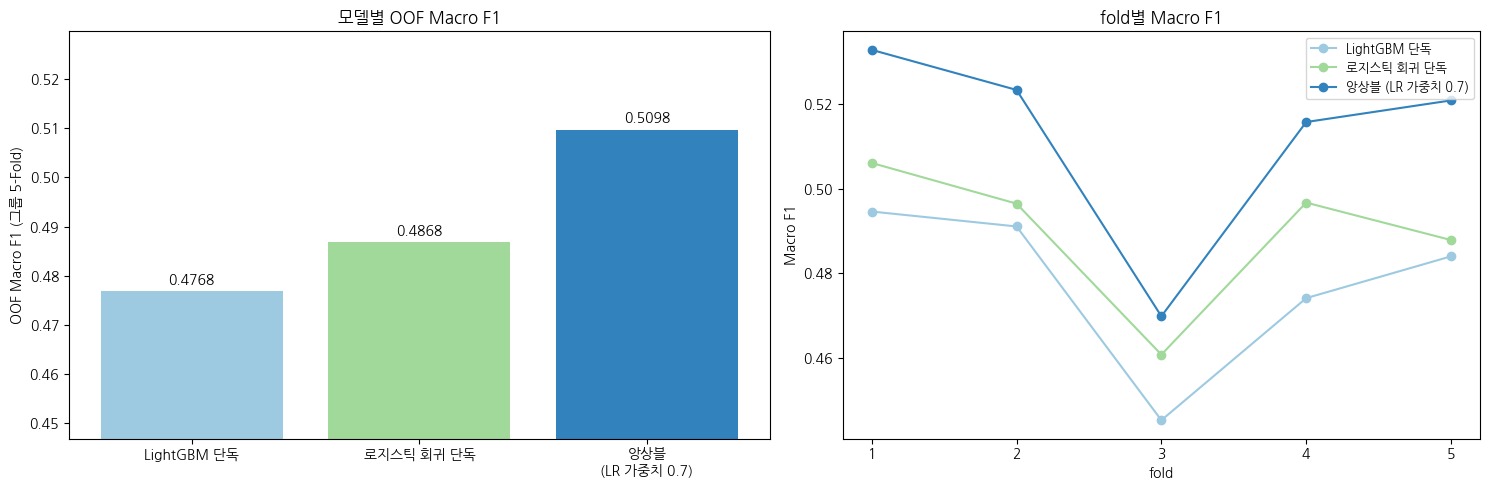

                  OOF Macro F1  fold 평균  fold 표준편차
LightGBM 단독             0.4768   0.4778     0.0177
로지스틱 회귀 단독              0.4868   0.4896     0.0155
앙상블 (LR 가중치 0.7)        0.5098   0.5125     0.0220


In [16]:
# ===== 모델 성능 비교 그래프 (OOF 기준) =====
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib            # 한글 폰트 (0장에서 설치)
except ImportError:
    pass
plt.rcParams['axes.unicode_minus'] = False

def f1_of(P_or_pred, idx=None):
    pred = P_or_pred if P_or_pred.ndim == 1 else P_or_pred.argmax(1)
    if idx is None:
        return f1_score(y, pred, average='macro')
    return f1_score(y[idx], pred[idx], average='macro')

# 비교할 결과 모으기 (노트북에서 이미 계산된 OOF만 사용, 재학습 없음)
results = {'LightGBM 단독': oof_lgb}
if USE_LR_BLEND:
    results['로지스틱 회귀 단독'] = oof_lr
    results[f'앙상블\n(LR 가중치 {LR_W})'] = P_oof

names = list(results)
overall = [f1_of(results[n]) for n in names]
per_fold = {n: [f1_of(results[n], va) for _, va in folds] for n in names}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.1, 1]})

# (1) 전체 OOF Macro F1 막대그래프
colors = ['#9ecae1', '#a1d99b', '#3182bd', '#08519c'][:len(names)]
bars = axes[0].bar(names, overall, color=colors)
axes[0].bar_label(bars, fmt='%.4f', padding=3)
axes[0].set_ylim(min(overall) - 0.03, max(overall) + 0.02)
axes[0].set_ylabel('OOF Macro F1 (그룹 5-Fold)')
axes[0].set_title('모델별 OOF Macro F1')

# (2) fold별 점수 (점수가 얼마나 흔들리는지)
x = np.arange(1, len(folds) + 1)
for n, c in zip(names, colors):
    axes[1].plot(x, per_fold[n], marker='o', color=c, label=n.replace('\n', ' '))
axes[1].set_xticks(x); axes[1].set_xlabel('fold'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('fold별 Macro F1')
axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

summary = pd.DataFrame({'OOF Macro F1': overall,
                        'fold 평균': [np.mean(per_fold[n]) for n in names],
                        'fold 표준편차': [np.std(per_fold[n]) for n in names]},
                       index=[n.replace('\n', ' ') for n in names]).round(4)
print(summary.to_string())

## 9-1. 암종별 분석 (OOF 앙상블 기준)

Macro F1은 26개 암종 F1의 평균이라, **점수가 낮은 암종**과 **서로 헷갈리는 암종 쌍**을 아는 것이 개선의 출발점입니다.
- `실제 수`와 `예측 수`를 비교하면 모델이 특정 암종을 과하게 예측하는지 알 수 있습니다. (Train OOF에서는 COAD·STES를 과하게 예측하지 않습니다. 그런데 Test에서는 많이 예측된다면 모델 편향보다 **Test 분포 자체가 다를** 가능성이 큽니다.)
- 가장 많이 헷갈리는 쌍은 KIRC↔KIPAN, GBMLGG↔LGG입니다. 같은 환자가 두 코호트에 모두 들어 있어 변이 프로필이 똑같기 때문입니다 → 10-1의 중복 프로필 규칙

In [17]:
from sklearn.metrics import confusion_matrix

pred_oof = P_oof.argmax(1)
per_class = pd.DataFrame({'실제 수': np.bincount(y, minlength=K),
                          'OOF 예측 수': np.bincount(pred_oof, minlength=K),
                          'F1': f1_score(y, pred_oof, average=None).round(3)},
                         index=le.classes_).sort_values('F1')
print(per_class.to_string())

cm = confusion_matrix(y, pred_oof)
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:12], cm.shape))[0]
print('\n가장 많이 헷갈린 쌍 (실제 → 예측: 인원)')
for a, b in top:
    print(f'  {le.classes_[a]:>7} → {le.classes_[b]:<7} {cm[a, b]}')

        실제 수  OOF 예측 수     F1
THYM      98        70  0.143
SARC     198       221  0.234
KIRC     334       242  0.333
PCPG     147       171  0.340
PRAD     266       457  0.382
DLBC      38         9  0.383
PAAD     120       100  0.400
HNSC     223       225  0.406
CESC     155       137  0.418
OV       253       356  0.427
KIPAN    515       587  0.441
LUAD     184       157  0.469
LIHC     158       133  0.474
GBMLGG   461       346  0.486
LAML     158       220  0.503
BLCA     104        99  0.512
LGG      229       298  0.550
STES     379       401  0.567
BRCA     786       693  0.576
LUSC     178       202  0.605
TGCT     124       125  0.659
UCEC     198       194  0.694
THCA     324       263  0.702
COAD     223       193  0.779
ACC       72        56  0.875
SKCM     276       246  0.897

가장 많이 헷갈린 쌍 (실제 → 예측: 인원)
     KIRC → KIPAN   146
   GBMLGG → LGG     146
    KIPAN → KIRC    108
     BRCA → PRAD    73
     BRCA → OV      68
      LGG → GBMLGG  57
     THYM → LAML    37

In [18]:
# =====================================================================
#  중복 프로필 규칙 OOF 검증
# =====================================================================
# 목적: Test에 쓰기 전에, 같은 규칙을 Train 안에서 시뮬레이션해 점수가 오르는지 확인
# - 그룹 CV에서는 중복 쌍이 같은 fold에 묶여 이 상황이 생기지 않으므로,
#   이 검증만 일반 StratifiedKFold로 나눕니다 (Test 환자의 쌍둥이가 Train에 있는 상황을 흉내).
# - 모델 예측은 이미 계산된 P_oof를 그대로 쓰고, 규칙에 걸린 환자만 짝 라벨로 바꿉니다 (재학습 없음).
# - 짝 라벨 목록과 프로필 대조는 매번 '학습 쪽 4/5'로만 만듭니다.
from sklearn.model_selection import StratifiedKFold

DUP_MIN_PAIRS = 20
n_mut_tr = tr_stat[:, STAT_NAMES.index('n_total')]      # 행 단위 총 변이 수
lab_tr = le.classes_[y]                                  # Train 정답 (문자열)
base_pred = le.classes_[P_oof.argmax(1)].astype(object)  # 규칙 적용 전 OOF 예측

def build_pair_map(labels, hashes, min_pairs=DUP_MIN_PAIRS):
    """학습 데이터 안의 중복 쌍으로 짝 라벨 목록 + (프로필 해시 → 라벨 목록) 사전 만들기"""
    g = pd.Series(labels).groupby(hashes).agg(list)
    cnt = Counter(tuple(sorted(l)) for l in g if len(l) == 2)
    pm = {}
    for (a, b), n in cnt.items():
        if a != b and n >= min_pairs:
            pm[a], pm[b] = b, a
    return pm, g.to_dict()

def apply_dup_rule(pred, hashes, n_mut, pair_map, label_of, min_mut=0, max_size=99):
    """프로필이 학습 데이터와 똑같고, 그 라벨이 한 종류이며 짝 목록에 있으면 짝 라벨로 바꿈"""
    pred = np.asarray(pred, dtype=object).copy()
    hit = []
    for i, (h, m) in enumerate(zip(hashes, n_mut)):
        labs = label_of.get(h)
        if (labs and len(labs) <= max_size and len(set(labs)) == 1
                and labs[0] in pair_map and m >= min_mut):
            pred[i] = pair_map[labs[0]]
            hit.append(i)
    return pred, np.array(hit, dtype=int)

def simulate(min_mut, max_size, seeds=(42, 7, 2026)):
    deltas, n_hit, acc_rule, acc_model = [], 0, [], []
    for s in seeds:
        sim = base_pred.copy()
        for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=s).split(lab_tr, y):
            pm, label_of = build_pair_map(lab_tr[tr_idx], groups[tr_idx])
            new, hit = apply_dup_rule(base_pred[va_idx], groups[va_idx], n_mut_tr[va_idx],
                                      pm, label_of, min_mut, max_size)
            sim[va_idx] = new
            if len(hit):
                acc_rule.append((new[hit] == lab_tr[va_idx][hit]).mean())
                acc_model.append((base_pred[va_idx][hit] == lab_tr[va_idx][hit]).mean())
                n_hit += len(hit)
        deltas.append(f1_score(lab_tr, sim, average='macro') - f1_score(lab_tr, base_pred, average='macro'))
    return dict(min_mut=min_mut, max_size=max_size, 적용인원_평균=n_hit / len(seeds),
                F1_변화=np.mean(deltas), F1_변화_최소=np.min(deltas),
                규칙_정답률=np.mean(acc_rule) if acc_rule else np.nan,
                모델_정답률=np.mean(acc_model) if acc_model else np.nan)

print('규칙 적용 전 OOF Macro F1:', round(f1_score(lab_tr, base_pred, average='macro'), 4))
grid = pd.DataFrame([simulate(mm, ms) for mm in (0, 1, 3, 5) for ms in (1, 2, 99)])
print(grid.round(4).sort_values('F1_변화', ascending=False).to_string(index=False))

# 가장 좋은 조건을 10-1에서 사용 (F1_변화가 0 이하면 규칙을 끄는 것이 맞음)
best = grid.sort_values('F1_변화', ascending=False).iloc[0]
DUP_MIN_MUT, DUP_MAX_SIZE = int(best['min_mut']), int(best['max_size'])
if best['F1_변화'] <= 0:
    USE_DUP_RULE = False
print(f'\n선택: 최소 변이 수 {DUP_MIN_MUT}, Train 같은 프로필 최대 {DUP_MAX_SIZE}명 → USE_DUP_RULE = {USE_DUP_RULE}')
# 참고: 실제 Test에서는 모델이 Train의 쌍둥이 라벨을 외워서 예측하므로,
#       '모델_정답률'은 실제보다 낙관적입니다 → 실제 이득은 이 표보다 클 가능성이 큽니다.

규칙 적용 전 OOF Macro F1: 0.5098
 min_mut  max_size  적용인원_평균  F1_변화  F1_변화_최소  규칙_정답률  모델_정답률
       0         1 725.3333 0.0461    0.0451  0.9973  0.4027
       0         2 726.3333 0.0461    0.0452  0.9973  0.4021
       0        99 726.3333 0.0461    0.0452  0.9973  0.4021
       1         1 725.3333 0.0461    0.0451  0.9973  0.4027
       1         2 726.3333 0.0461    0.0452  0.9973  0.4021
       1        99 726.3333 0.0461    0.0452  0.9973  0.4021
       3         1 690.6667 0.0443    0.0432  1.0000  0.4011
       3         2 690.6667 0.0443    0.0432  1.0000  0.4011
       3        99 690.6667 0.0443    0.0432  1.0000  0.4011
       5         1 650.6667 0.0417    0.0400  1.0000  0.4003
       5         2 650.6667 0.0417    0.0400  1.0000  0.4003
       5        99 650.6667 0.0417    0.0400  1.0000  0.4003

선택: 최소 변이 수 0, Train 같은 프로필 최대 2명 → USE_DUP_RULE = True


참고: 고변이 암종(UCEC, SKCM, COAD, STES) 실제 수 = 1076
 정규화  NB 단독 Macro F1  고변이군 Macro F1  저·중변이군 Macro F1  최대확률 평균  고변이 암종 예측 수
none          0.2106         0.1059           0.2042   0.6839         3402
sqrt          0.1798         0.1043           0.1697   0.3727         2710
mean          0.0802         0.0037           0.0825   0.1840          147
변이 유전자 수  환자 수         주요 암종(상위 3)  LightGBM 정확도  로지스틱 회귀 정확도  앙상블 정확도  앙상블 Macro F1  평균 최대확률
      0개    94    THYM, THCA, LAML         0.128        0.128    0.128         0.015    0.386
     1~5  1132    THCA, BRCA, LAML         0.466        0.451    0.470         0.213    0.487
    6~10  1262 BRCA, GBMLGG, KIPAN         0.432        0.441    0.452         0.308    0.397
   11~20  1627 KIPAN, BRCA, GBMLGG         0.462        0.461    0.487         0.390    0.347
   21~50  1253   STES, KIPAN, HNSC         0.488        0.528    0.548         0.501    0.361
  51~100   446    LUSC, STES, SKCM         0.675        0.682    0.709         0.538    0

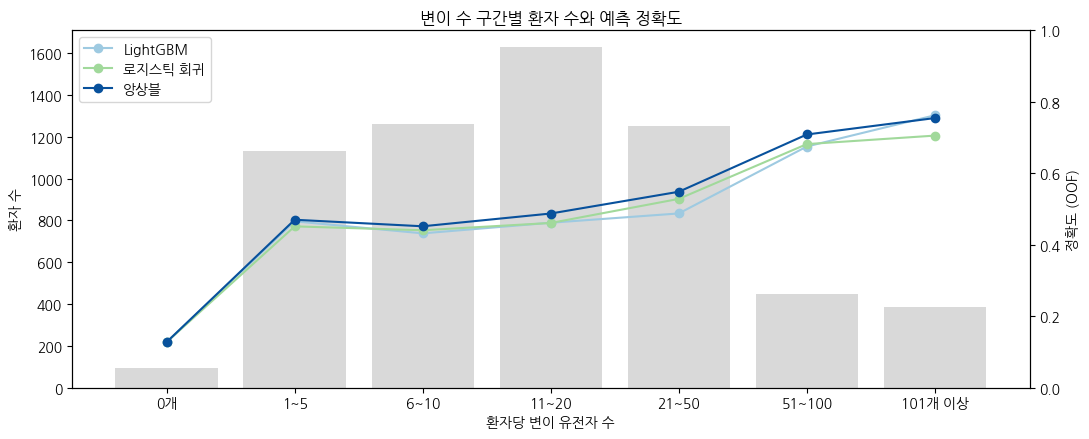

In [19]:
# =====================================================================
#  정규화 방식 빠른 비교 (나이브 베이즈 단독, 1~2분)
# =====================================================================
# LightGBM을 다시 돌리기 전에, 나이브 베이즈 점수 자체가 어떻게 바뀌는지 먼저 확인
n_total_tr = tr_stat[:, STAT_NAMES.index('n_total')]
HIGH = n_total_tr >= np.quantile(n_total_tr, 0.90)       # 고변이 환자 (분석용 구분)
HYPER_CLS = ['UCEC', 'SKCM', 'COAD', 'STES']             # 변이가 많은 암종

rows = []
for norm in ['none', 'sqrt', 'mean']:
    P_nb = np.zeros((len(y), K), np.float32)
    for tr_idx, va_idx in folds:                          # 기존과 같은 그룹 5-Fold
        P_nb[va_idx] = _nb_fit_predict(pick(tr_ns, tr_idx), y[tr_idx], pick(tr_ns, va_idx), norm)
    pred = P_nb.argmax(1)
    hyper_idx = le.transform(HYPER_CLS)
    rows.append({'정규화': norm,
                 'NB 단독 Macro F1': f1_score(y, pred, average='macro'),
                 '고변이군 Macro F1': f1_score(y[HIGH], pred[HIGH], average='macro', labels=np.unique(y[HIGH])),
                 '저·중변이군 Macro F1': f1_score(y[~HIGH], pred[~HIGH], average='macro', labels=np.unique(y[~HIGH])),
                 '최대확률 평균': P_nb.max(1).mean(),          # 1에 가까울수록 극단적으로 쏠림
                 '고변이 암종 예측 수': int(np.isin(pred, hyper_idx).sum())})
print(f"참고: 고변이 암종({', '.join(HYPER_CLS)}) 실제 수 = {int(np.isin(y, le.transform(HYPER_CLS)).sum())}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
# 판단: NB 단독 F1이 크게 떨어지지 않으면서 '최대확률 평균'과 '고변이 암종 예측 수'가 줄어드는 방식을 고름
#       → 셀 C의 NB_NORM을 바꾸고 6장(LightGBM) → 8장(앙상블) → 9-1장을 다시 실행
#       → 앙상블 OOF Macro F1이 기존 0.5098보다 오를 때만 채택 (약 20분 소요)


# =====================================================================
#  변이 수 구간별 성능 분석 (발표용, 재학습 없음)
# =====================================================================
# 주제 ①(저변이군 한계) + 주제 ④(고변이군)를 표 하나로 정량화
n_gene_tr = tr_stat[:, STAT_NAMES.index('n_gene')]
BINS   = [-1, 0, 5, 10, 20, 50, 100, np.inf]
LABELS = ['0개', '1~5', '6~10', '11~20', '21~50', '51~100', '101개 이상']
bin_of = pd.cut(n_gene_tr, BINS, labels=LABELS)

models = {'LightGBM': oof_lgb, '로지스틱 회귀': oof_lr, '앙상블': P_oof}
preds = {k: v.argmax(1) for k, v in models.items()}

rows = []
for b in LABELS:
    idx = np.where(bin_of == b)[0]
    if len(idx) == 0:
        continue
    yt = y[idx]
    r = {'변이 유전자 수': b, '환자 수': len(idx),
         '주요 암종(상위 3)': ', '.join(pd.Series(le.classes_[yt]).value_counts().head(3).index)}
    for k, p in preds.items():
        r[f'{k} 정확도'] = (p[idx] == yt).mean()
    r['앙상블 Macro F1'] = f1_score(yt, preds['앙상블'][idx], average='macro', labels=np.unique(yt))
    r['평균 최대확률'] = P_oof[idx].max(1).mean()
    rows.append(r)
burden_table = pd.DataFrame(rows)
print(burden_table.round(3).to_string(index=False))

# 구간별로 가장 많이 헷갈린 쌍 (앙상블 기준)
print('\n구간별 상위 오분류 쌍 (실제 → 예측: 인원)')
for b in LABELS:
    idx = np.where(bin_of == b)[0]
    if len(idx) == 0:
        continue
    wrong = pd.Series([f'{le.classes_[a]}→{le.classes_[c]}' for a, c in zip(y[idx], preds['앙상블'][idx]) if a != c])
    print(f'  {b:>8}: ' + ', '.join(f'{k} {v}' for k, v in wrong.value_counts().head(4).items()))

# 그래프: 구간별 환자 수(막대) + 모델별 정확도(선)
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(burden_table['변이 유전자 수'], burden_table['환자 수'], color='#d9d9d9')
ax1.set_ylabel('환자 수'); ax1.set_xlabel('환자당 변이 유전자 수')
ax2 = ax1.twinx()
for k, c in zip(models, ['#9ecae1', '#a1d99b', '#08519c']):
    ax2.plot(burden_table['변이 유전자 수'], burden_table[f'{k} 정확도'], marker='o', color=c, label=k)
ax2.set_ylabel('정확도 (OOF)'); ax2.set_ylim(0, 1); ax2.legend(loc='upper left')
plt.title('변이 수 구간별 환자 수와 예측 정확도')
plt.tight_layout(); plt.show()

중복 프로필 그룹 451개 (환자 1016명)
 └ 라벨이 서로 다른 그룹 447개 (환자 1005명)
 └ 그중 변이 0개(모두 WT) 그룹: 환자 94명, 라벨 15종 → {'THYM': np.int64(30), 'THCA': np.int64(18), 'LAML': np.int64(12), 'BRCA': np.int64(5), 'KIPAN': np.int64(4), 'PRAD': np.int64(4)}

라벨이 충돌하는 조합 (상위 8):
y
KIPAN + KIRC    272
GBMLGG + LGG    173
LGG + THCA        1

줄일 수 없는 오류: 511명 (8.2%)
이론상 상한 — 정확도 0.9176 | Macro F1 0.9373
현재 앙상블 — 정확도 0.5164 | Macro F1 0.5098

중복 때문에 상한이 1.0 미만인 암종:
        상한 F1  현재 F1
KIRC    0.586  0.333
LGG     0.609  0.550
KIPAN   0.730  0.441
THYM    0.754  0.143
GBMLGG  0.810  0.486
LAML    0.961  0.503
THCA    0.970  0.702
PCPG    0.990  0.340
CESC    0.990  0.418
SARC    0.992  0.234
PRAD    0.992  0.382
LUSC    0.994  0.605
PAAD    0.996  0.400
BRCA    0.997  0.576
STES    0.997  0.567
신뢰도 하위 → 상위 10분위별 정답률
         환자수  평균신뢰도    정답률  평균엔트로피  변이유전자수_중앙값
q                                             
0~10%    621  0.138  0.203   2.830        13.0
10~20%   620  0.178  0.235   2.708        12.0
20~30%   620  0.2

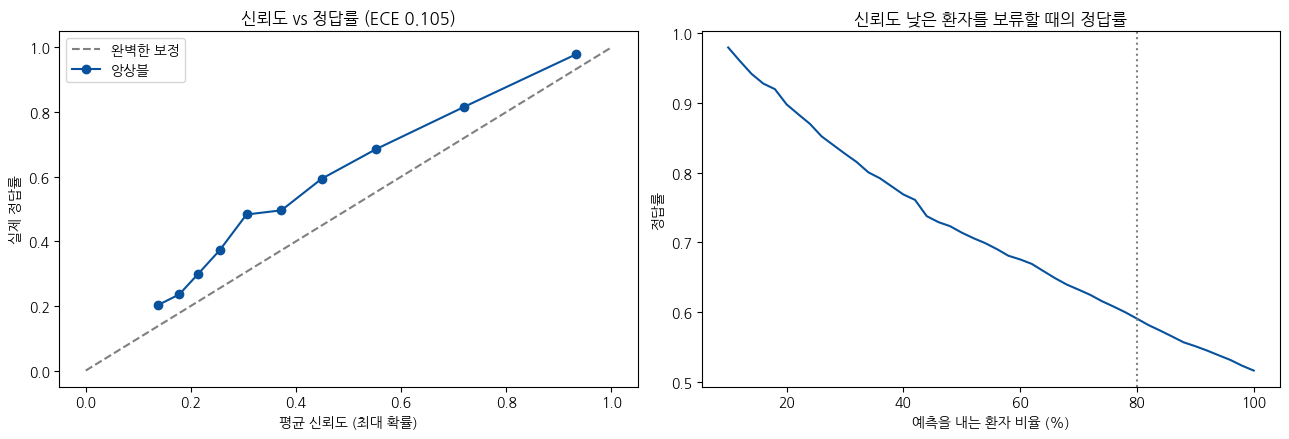

In [20]:
# =====================================================================
#  이론상 최대 성능 (중복 프로필의 라벨 충돌)
# =====================================================================
# 생각: 변이 프로필이 똑같은 환자들은 어떤 모델이든 '같은 답'을 낼 수밖에 없음
#       → 한 프로필에 라벨이 여러 개면, 그중 최소 일부는 반드시 틀림 (줄일 수 없는 오류)
# 방법: 프로필마다 '가장 많은 라벨'을 답으로 내는 가상의 완벽한 모델(오라클)을 만들고,
#       중복이 아닌 환자는 전부 맞힌다고 가정 → 이 데이터로 도달 가능한 점수의 상한
# 주의: 중복이 아닌 환자도 실제로는 틀리므로, 진짜 상한은 이보다 더 낮음 (느슨한 상한)
lab_tr = le.classes_[y]
g = pd.DataFrame({'h': groups, 'y': lab_tr})
grp = g.groupby('h')['y'].agg(list)
dup = grp[grp.str.len() >= 2]
conflict = dup[dup.apply(lambda l: len(set(l)) >= 2)]

print(f'중복 프로필 그룹 {len(dup)}개 (환자 {dup.str.len().sum()}명)')
print(f' └ 라벨이 서로 다른 그룹 {len(conflict)}개 (환자 {conflict.str.len().sum()}명)')

# 변이가 하나도 없는 환자(모두 WT) 그룹은 따로 표시
n_gene_tr = tr_stat[:, STAT_NAMES.index('n_gene')]
wt_hash = groups[n_gene_tr == 0][0] if (n_gene_tr == 0).any() else None
if wt_hash is not None:
    wt = pd.Series(grp[wt_hash]).value_counts()
    print(f' └ 그중 변이 0개(모두 WT) 그룹: 환자 {wt.sum()}명, 라벨 {len(wt)}종 → {dict(wt.head(6))}')

# 충돌 그룹의 라벨 조합 (WT 그룹 제외)
combo = conflict.drop(index=wt_hash, errors='ignore').apply(lambda l: ' + '.join(sorted(set(l)))).value_counts()
print('\n라벨이 충돌하는 조합 (상위 8):')
print(combo.head(8).to_string())

# 오라클 예측: 프로필마다 최다 라벨 (동점이면 라벨을 번갈아 배정해 특정 암종 쏠림 방지)
oracle = lab_tr.astype(object).copy()
rot = Counter()
for h, labs in conflict.items():
    vc = pd.Series(labs).value_counts()
    tied = sorted(vc[vc == vc.max()].index)
    key = tuple(tied)
    choice = tied[rot[key] % len(tied)]
    rot[key] += 1
    oracle[np.where(groups == h)[0]] = choice

ceil_acc = (oracle == lab_tr).mean()
ceil_f1 = f1_score(lab_tr, oracle, average='macro')
cur_pred = le.classes_[P_oof.argmax(1)]
print(f'\n줄일 수 없는 오류: {int((oracle != lab_tr).sum())}명 ({(oracle != lab_tr).mean():.1%})')
print(f'이론상 상한 — 정확도 {ceil_acc:.4f} | Macro F1 {ceil_f1:.4f}')
print(f'현재 앙상블 — 정확도 {(cur_pred == lab_tr).mean():.4f} | Macro F1 {f1_score(lab_tr, cur_pred, average="macro"):.4f}')

# 암종별 상한 F1 (1.0보다 낮은 암종만 = 중복 때문에 원천적으로 다 맞힐 수 없는 암종)
ceil_cls = pd.DataFrame({'상한 F1': f1_score(lab_tr, oracle, average=None, labels=le.classes_),
                         '현재 F1': f1_score(lab_tr, cur_pred, average=None, labels=le.classes_)},
                        index=le.classes_)
print('\n중복 때문에 상한이 1.0 미만인 암종:')
print(ceil_cls[ceil_cls['상한 F1'] < 0.999].sort_values('상한 F1').round(3).to_string())


# =====================================================================
#  예측 신뢰도와 정답률 (예측 보류 기준 제안)
# =====================================================================
conf = P_oof.max(1)                                              # 신뢰도 = 가장 높은 암종 확률
ent = -(P_oof * np.log(np.clip(P_oof, 1e-12, 1))).sum(1)         # 엔트로피 (높을수록 헷갈림)
correct = (P_oof.argmax(1) == y)

# (1) 신뢰도 10분위별 정답률
q = pd.qcut(conf, 10, labels=[f'{i*10}~{(i+1)*10}%' for i in range(10)])
dec = pd.DataFrame({'q': q, 'conf': conf, 'ok': correct, 'ent': ent, 'n_gene': n_gene_tr})
dec_tab = dec.groupby('q', observed=True).agg(환자수=('ok', 'size'), 평균신뢰도=('conf', 'mean'),
                                               정답률=('ok', 'mean'), 평균엔트로피=('ent', 'mean'),
                                               변이유전자수_중앙값=('n_gene', 'median'))
print('신뢰도 하위 → 상위 10분위별 정답률')
print(dec_tab.round(3).to_string())

# 보정 오차 (ECE): 신뢰도와 실제 정답률의 차이 — 작을수록 확률을 믿을 수 있음
ece = (dec_tab['환자수'] / len(y) * (dec_tab['평균신뢰도'] - dec_tab['정답률']).abs()).sum()
print(f'\nECE (기대 보정 오차) = {ece:.3f}')

# (2) 신뢰도 낮은 환자를 보류하면? (커버리지 = 예측을 내는 환자 비율)
rows = []
order = np.argsort(-conf)                                        # 신뢰도 높은 순
for cov in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    keep = order[:int(len(y) * cov)]
    rows.append({'커버리지': f'{cov:.0%}', '신뢰도 기준(이상)': conf[keep].min(),
                 '정답률': correct[keep].mean(),
                 'Macro F1': f1_score(y[keep], P_oof[keep].argmax(1), average='macro', labels=np.unique(y[keep])),
                 '보류 환자 정답률': correct[order[len(keep):]].mean() if cov < 1 else np.nan})
cov_tab = pd.DataFrame(rows)
print('\n신뢰도 하위 환자를 보류할 때')
print(cov_tab.round(3).to_string(index=False))

# (3) 보류 대상(하위 20%)이 어떤 환자인지
low = conf <= np.quantile(conf, 0.2)
print(f'\n신뢰도 하위 20% 환자: 변이 유전자 수 중앙값 {np.median(n_gene_tr[low]):.0f}개 '
      f'(나머지 {np.median(n_gene_tr[~low]):.0f}개), 변이 0개 비율 {(n_gene_tr[low] == 0).mean():.1%}')
print('하위 20%에 많은 암종 (해당 암종 환자 중 하위 20%에 속한 비율):')
share = pd.Series(low).groupby(lab_tr).mean().sort_values(ascending=False)
print(share.head(8).round(3).to_string())

# 그래프: 신뢰도-정답률(보정 곡선) + 커버리지-정답률
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot([0, 1], [0, 1], ls='--', color='gray', label='완벽한 보정')
ax[0].plot(dec_tab['평균신뢰도'], dec_tab['정답률'], marker='o', color='#08519c', label='앙상블')
ax[0].set_xlabel('평균 신뢰도 (최대 확률)'); ax[0].set_ylabel('실제 정답률')
ax[0].set_title(f'신뢰도 vs 정답률 (ECE {ece:.3f})'); ax[0].legend()
covs = np.linspace(0.1, 1.0, 46)
accs = [correct[order[:int(len(y) * c)]].mean() for c in covs]
ax[1].plot(covs * 100, accs, color='#08519c')
ax[1].axvline(80, ls=':', color='gray')
ax[1].set_xlabel('예측을 내는 환자 비율 (%)'); ax[1].set_ylabel('정답률')
ax[1].set_title('신뢰도 낮은 환자를 보류할 때의 정답률')
plt.tight_layout(); plt.show()

In [21]:
for k in (1, 3, 5):
    acc = (np.argsort(-P_oof, 1)[:, :k] == y[:, None]).any(1).mean()
    print(f'상위 {k}개 안 정답 포함: {acc:.1%}')

상위 1개 안 정답 포함: 51.6%
상위 3개 안 정답 포함: 77.4%
상위 5개 안 정답 포함: 86.4%


## 10. 전체 Train으로 재학습 → Test 예측 (시드 앙상블)

LightGBM은 매 트리마다 피처 30%와 데이터 80%를 무작위로 뽑기 때문에, 시드에 따라 예측이 조금씩 달라집니다.
`SEEDS`의 시드마다 따로 학습한 뒤 **확률을 평균**하면 우연한 흔들림이 상쇄되어 최종(Private) 점수가 안정됩니다. OOF로 무언가를 고르는 과정이 없어 과적합 위험이 거의 없습니다.
학습 시간은 시드 수만큼 늘어납니다 (교차검증은 시드 1개로 그대로 진행).

In [22]:
N_FINAL = int(np.mean(best_iters) * 1.1)     # 데이터가 1/0.8배 많아지므로 반복 수를 조금 늘림
print('최종 반복 수:', N_FINAL)

feat = TreeFeaturizer().fit(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)        # Train으로만 fit
X_train = feat.transform(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)
X_test  = feat.transform(te_all, te_ns, te_stat, te_codon, te_trans)           # Test는 transform만
if USE_NB_FEATURES:                                   # Train 전체로 중첩 점수, Test는 예측만
    F_train, F_test = nb_features(tr_ns, y, groups, te_ns)
    X_train, X_test = add_nb(X_train, F_train), add_nb(X_test, F_test)
ex = None
if USE_EXTRA:                                         # Train 전체로 fit, Test는 transform만
    ex = ExtraTreeFeaturizer().fit(tr_ns, tr_codon, tr_stat)
    X_train = add_extra(X_train, ex.transform(tr_ns, tr_codon, tr_stat))
    X_test  = add_extra(X_test, ex.transform(te_ns, te_codon, te_stat))

# 시드 앙상블: 시드만 바꿔 여러 번 학습하고 확률 평균
final_lgbs = []
P_lgb = np.zeros((X_test.shape[0], K))
for s in SEEDS:
    m = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': N_FINAL, 'random_state': s}).fit(X_train, y)
    final_lgbs.append(m)
    P_lgb += m.predict_proba(X_test) / len(SEEDS)
    print(f'  시드 {s} 학습 완료')
P_test = (1 - LR_W) * P_lgb

lf, final_lr = None, None
if LR_W > 0:
    lf = LinearFeaturizer().fit(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)                 # Train으로만 fit
    final_lr = make_lr().fit(lf.transform(tr_all, tr_ns, tr_stat, tr_codon, tr_trans), y)
    P_test += LR_W * final_lr.predict_proba(lf.transform(te_all, te_ns, te_stat, te_codon, te_trans))

test_pred = le.inverse_transform(P_test.argmax(1))

최종 반복 수: 174


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  시드 42 학습 완료


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  시드 7 학습 완료


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  시드 2026 학습 완료


## 10-1. 후처리: 중복 프로필 규칙

Train에서 변이 프로필이 똑같은 환자 쌍은 거의 모두 **KIPAN+KIRC** 또는 **GBMLGG+LGG** 조합입니다.
KIPAN(신장암 전체)은 KIRC를, GBMLGG(뇌종양 전체)는 LGG를 포함하는 코호트라서 **같은 환자가 두 라벨로 한 번씩** 등록된 것입니다.
따라서 Test 환자의 프로필이 Train의 KIRC 환자 한 명과 똑같다면, Test 쪽은 **짝 라벨인 KIPAN**일 가능성이 높습니다. 모델은 Train에서 그 프로필을 KIRC로 외웠기 때문에 그대로 두면 틀립니다.

- 짝 라벨 목록(`PAIR_MAP`)은 **Train 안의 중복 쌍만 세어서** 만듭니다 (20쌍 이상 나온 조합만).
- Test는 각 행의 해시값만 계산해 Train과 대조합니다. Test로 학습하거나 Test 통계를 쓰지 않습니다.
- Train에 짝이 이미 두 개 다 있거나(라벨 2종), 짝 목록에 없는 라벨이면 모델 예측을 그대로 둡니다.



In [23]:
# =====================================================================
#  검증된 조건으로 Test에 적용
# =====================================================================
test_pred_model = np.asarray(test_pred, dtype=object).copy()
test_pred = test_pred_model.copy()

if USE_DUP_RULE:
    # (1) Train 전체의 중복 쌍으로 짝 라벨 목록 만들기 (Train만 사용)
    PAIR_MAP, label_of = build_pair_map(lab_tr, groups)
    print('짝 라벨 목록:', PAIR_MAP)

    # (2) Test 각 행의 프로필 해시를 Train과 대조 (행 단위 계산, Test 통계 사용 없음)
    test_hash = pd.util.hash_pandas_object(test[GENES], index=False).values
    n_mut_te = te_stat[:, STAT_NAMES.index('n_total')]
    test_pred, hit = apply_dup_rule(test_pred_model, test_hash, n_mut_te, PAIR_MAP, label_of,
                                    DUP_MIN_MUT, DUP_MAX_SIZE)
    print(f'Train과 프로필이 같은 Test 환자 {np.isin(test_hash, groups).sum()}명 중 규칙 적용 {len(hit)}명, '
          f'예측이 바뀐 환자 {(test_pred[hit] != test_pred_model[hit]).sum()}명')
    if len(hit):
        print(pd.crosstab(pd.Series(test_pred_model[hit], name='모델 예측'),
                          pd.Series(test_pred[hit], name='규칙 적용 후')).to_string())

짝 라벨 목록: {'KIPAN': 'KIRC', 'KIRC': 'KIPAN', 'GBMLGG': 'LGG', 'LGG': 'GBMLGG'}
Train과 프로필이 같은 Test 환자 266명 중 규칙 적용 222명, 예측이 바뀐 환자 219명
규칙 적용 후  GBMLGG  KIPAN  KIRC  LGG
모델 예측                            
GBMLGG        0      0     0   46
KIPAN         0      0    59    0
KIRC          0     57     1    0
LGG          52      0     0    2
PRAD          0      1     2    0
THYM          0      0     2    0


## 11. 제출 파일 저장

In [24]:
assert (submission['ID'].values == test['ID'].values).all()
submission['SUBCLASS'] = test_pred
out_name = 'submission_lightgbm_final_dup.csv' if USE_DUP_RULE else 'submission_lightgbm_final.csv'
out_path = os.path.join(DATA_DIR, out_name)
submission.to_csv(out_path, index=False, encoding='utf-8')
print('저장:', out_path)
# Test 예측 분포 점검: Train 비율대로라면 몇 명이 나와야 하는지와 비교 (확인용, 예측은 바꾸지 않음)
dist = pd.DataFrame({'Test 예측 수': submission['SUBCLASS'].value_counts(),
                     'Train 비율 기준 기대 수': (train['SUBCLASS'].value_counts(normalize=True) * len(test)).round(0)}).fillna(0)
dist['배율'] = (dist['Test 예측 수'] / dist['Train 비율 기준 기대 수']).round(2)
print(dist.sort_values('Test 예측 수', ascending=False).to_string())

저장: /content/sample_data/submission_lightgbm_final_dup.csv
          Test 예측 수  Train 비율 기준 기대 수    배율
SUBCLASS                                   
STES            486             156.0  3.12
COAD            434              92.0  4.72
KIPAN           218             211.0  1.03
BRCA            204             323.0  0.63
OV              108             104.0  1.04
PRAD            107             109.0  0.98
GBMLGG          103             189.0  0.54
KIRC             94             137.0  0.69
UCEC             73              81.0  0.90
THCA             73             133.0  0.55
SKCM             65             113.0  0.58
LUSC             65              73.0  0.89
HNSC             58              92.0  0.63
LUAD             57              76.0  0.75
LGG              56              94.0  0.60
THYM             49              40.0  1.23
LIHC             41              65.0  0.63
CESC             39              64.0  0.61
PCPG             37              60.0  0.62
TGCT             

**Test 예측 분포를 보정하지 않는 이유**
- 배율이 크게 나오는 암종(예: COAD, STES)이 있어도, Train OOF에서는 이 암종들을 과하게 예측하지 않습니다(9-1의 `OOF 예측 수`). 모델 편향이 아니라 **Test의 실제 암종 비율이 Train과 다를** 가능성이 큽니다.
- Test 예측 분포에 맞춰 확률을 조정하면 **Test 데이터의 통계로 예측을 바꾸는 것**이라 규정 위반 소지가 있습니다.
- 예전에 판정 보정값을 뺐을 때 리더보드가 0.3162 → 0.3246으로 올랐습니다. 분포 보정은 이 대회에서 손해였습니다.

## 12. 추론에 사용한 모델 파일 저장

Test 예측에 실제로 쓴 객체를 `./data/model/`에 저장합니다. 제출할 때 이 폴더를 압축해서 다운로드 링크로 올리거나 메일에 첨부합니다.

| 파일 | 내용 |
|---|---|
| `lgbm_seed{시드}.txt` | 최종 LightGBM 모델 (시드별, LightGBM 기본 텍스트 형식) |
| `preprocess_and_lr.pkl` | 트리용·선형용·LightGBM 전용 특징 변환기(어휘·기준값·유전자 쌍 목록), 로지스틱 회귀 모델, LabelEncoder, 앙상블 가중치, 설정값 |

나이브 베이즈 점수는 Train으로 다시 계산되므로(5-1장의 `nb_features`) 별도 파일 없이 같은 코드로 재현됩니다.

In [25]:
for s, m in zip(SEEDS, final_lgbs):
    m.booster_.save_model(os.path.join(MODEL_DIR, f'lgbm_seed{s}.txt'))

with open(os.path.join(MODEL_DIR, 'preprocess_and_lr.pkl'), 'wb') as fp:
    pickle.dump({'tree_featurizer': feat, 'extra_tree_featurizer': ex, 'linear_featurizer': lf, 'logistic_regression': final_lr,
                 'label_encoder': le, 'LR_W': LR_W, 'N_FINAL': N_FINAL, 'SEEDS': SEEDS,
                 'switches': dict(USE_NEW_FEATURES=USE_NEW_FEATURES, USE_MORE_FEATURES=USE_MORE_FEATURES,
                                  USE_AA_GROUPS=USE_AA_GROUPS, USE_NB_FEATURES=USE_NB_FEATURES,
                                  USE_PAIR_FEATURES=USE_PAIR_FEATURES, USE_COMBO_FEATURES=USE_COMBO_FEATURES, USE_POS_BINS=USE_POS_BINS)}, fp)

for fn in sorted(os.listdir(MODEL_DIR)):
    print(f'{fn:<28} {os.path.getsize(os.path.join(MODEL_DIR, fn)) / 1e6:.1f} MB')

lgbm_seed2026.txt            8.5 MB
lgbm_seed42.txt              8.5 MB
lgbm_seed7.txt               8.5 MB
preprocess_and_lr.pkl        9.8 MB
